In [ ]:
%pip install pygam

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.gam.api import GLMGam, BSplines, CyclicCubicSplines
from statsmodels.genmod.families.family import Tweedie
from statsmodels.genmod.families.links import log
from pygam import GAM, LinearGAM, PoissonGAM, s
from statsmodels.graphics.tsaplots import (
    plot_acf,
    plot_pacf
)
from statsmodels.tsa.seasonal import STL

from crossbasis import CrossBasis 


In [144]:
df = pd.read_csv("data.csv")

df.columns = ["Year", "Week", "From", "temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV", "H1", "H3", "B", "AandB"]

mete_col = ["temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV"]
flu_col = ["H1", "H3", "B", "AandB"]

df["From"] = pd.to_datetime(df["From"])

# Cross basis matrix construction for all Exposures 
cb_exp_list = []
var_df = 3
lag_df = 3
cb = CrossBasis(var_basis="bs", var_df=var_df, var_kwargs={"include_intercept": True}, lag_basis="bs", lag_df=lag_df, lag_kwargs={"include_intercept": True}, max_lag=4, na_action="fill_zero")
for col in mete_col:
    if col != "WS": # Wind speed contains null value
        tmp_cb = cb.fit_transform(df[col].values)
        cb_exp_list.append(pd.DataFrame(tmp_cb, columns=[f"{col}_basis_{i}" for i in range(tmp_cb.shape[1])]))
X_exposure = pd.concat(cb_exp_list, axis=1)
exp_names = " + ".join(X_exposure.columns)

model_data = pd.concat([df, X_exposure], axis=1)
model_data.drop(columns=["From"], inplace=True)

formula = f"H1 ~ {exp_names}"
ss = CyclicCubicSplines(df[["Year", "Week"]], df=[4, 4])
NegativeBinomial_gam_model = GLMGam.from_formula(formula, data=model_data, smoother=ss, family=sm.families.NegativeBinomial())
Tweddie_gam_model = GLMGam.from_formula(formula, data=model_data, smoother=ss, family=Tweedie(link=log(), var_power=1.5))


C:\Users\yanss\AppData\Local\Temp\ipykernel_16960\426396241.py:27: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  NegativeBinomial_gam_model = GLMGam.from_formula(formula, data=model_data, smoother=ss, family=sm.families.NegativeBinomial())
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\genmod\families\links.py:1423: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  _link_deprecation_warning("log", "Log")


In [ ]:
# selection for the value of degree of freedom for both dimensions
best_aic = float('inf')
best_var_df = None
best_lag_df = None

# Grid search: try var_df from 3 to 6, and lag_df from 3 to 5
for v_df in:
    for l_df in:
        
        # 1. Initialize cross-basis with candidate df
        cp = CrossPred(var_basis="ns", var_df=v_df, lag_basis="ns", lag_df=l_df, max_lag=21, na_action="drop")
        W = cp.fit(temperature)
        
        # 2. Align your target variable with the dropped lag rows
        # W has fewer rows than the raw data due to na_action="drop"
        y_aligned = deaths[-W.shape[0]:] 
        X = sm.add_constant(W)
        
        # 3. Fit model and check AIC
        model = sm.GLM(y_aligned, X, family=sm.families.Poisson()).fit()
        
        print(f"var_df: {v_df}, lag_df: {l_df} -> AIC: {model.aic:.2f}")
        
        if model.aic < best_aic:
            best_aic = model.aic
            best_var_df = v_df
            best_lag_df = l_df

# result with lower AIC value better
print(f"\n🏆 Best Configuration: var_df={best_var_df}, lag_df={best_lag_df}")

In [ ]:
df = pd.read_csv("data.csv")

cp = CrossPred(var_basis="ns", var_df=5, lag_basis="ns", lag_df=4, max_lag=4)
W = cp.fit(df["Mean temperature (°C)"].to_numpy())

dlnm_df = pd.DataFrame(df["H1"], columns=["H1"])
for i in range(W.shape[1]):
    dlnm_df[f"cb_{i}"] = W[:, i]

clean_dlnm_df = dlnm_df.dropna() 

y_clean = clean_dlnm_df["H1"]
X_clean = clean_dlnm_df[[col for col in clean_dlnm_df.columns if col.startswith("cb_")]]


gam = PoissonGAM(s(0)).fit(X_clean, y_clean)
#gam = GAM(s(0), distribution="poisson", link="log").fit(X_clean, y_clean)
model = gam.predict(X_clean)

gam.summary()


c:\Users\yanss\anaconda3\Lib\site-packages\crossbasis\crossbasis.py:185: UserWarning: CrossBasis.transform: 4 rows with NaNs from lag padding (first 4 row indices: [0 1 2 3]). These rows will produce NaN in W.
  warnings.warn(
c:\Users\yanss\anaconda3\Lib\site-packages\crossbasis\crosspred.py:447: UserWarning: CrossPred.fit: 4 rows with NaNs from lag padding. These rows will need to be dropped before GLM fitting.
  warnings.warn(
c:\Users\yanss\anaconda3\Lib\site-packages\pygam\pygam.py:2859: FutureWarning: Series.ravel is deprecated. The underlying array is already 1D, so ravel is not necessary.  Use `to_numpy()` for conversion to a numpy array instead.
  y = y.ravel()
c:\Users\yanss\anaconda3\Lib\site-packages\pygam\links.py:181: RuntimeWarning: overflow encountered in exp
  return np.exp(lp)
c:\Users\yanss\anaconda3\Lib\site-packages\pygam\links.py:196: RuntimeWarning: divide by zero encountered in divide
  return 1.0 / mu
c:\Users\yanss\anaconda3\Lib\site-packages\pygam\pygam.py:63

OptimizationError: PIRLS optimization has diverged.
Try increasing regularization, or specifying an initial value for self.coef_

In [145]:
res_bs = NegativeBinomial_gam_model.fit()
print(res_bs.summary())

c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_result

                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1253
Model:                         GLMGam   Df Residuals:                  1175.71
Model Family:        NegativeBinomial   Df Model:                        76.29
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -5918.2
Date:                Sat, 07 Nov 2026   Deviance:                       5155.2
Time:                        14:21:30   Pearson chi2:                 9.01e+03
No. Iterations:                  1000   Pseudo R-squ. (CS):             0.6514
Covariance Type:            nonrobust                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             3.7465      0.42

c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_result

In [147]:
res_bs = Tweddie_gam_model.fit()
print(res_bs.summary())

c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_result

                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1253
Model:                         GLMGam   Df Residuals:                  1182.47
Model Family:                 Tweedie   Df Model:                        69.53
Link Function:                    log   Scale:                          27.288
Method:                         PIRLS   Log-Likelihood:                -5181.2
Date:                Sat, 07 Nov 2026   Deviance:                       23439.
Time:                        14:22:12   Pearson chi2:                 3.23e+04
No. Iterations:                   170   Pseudo R-squ. (CS):             0.3126
Covariance Type:            nonrobust                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             3.8965      0.74

c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_result

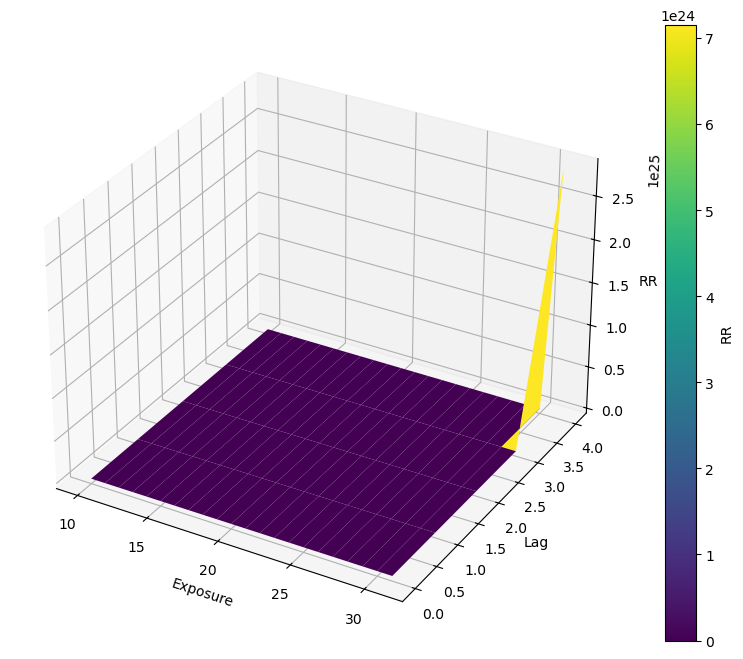

In [33]:
n_cb = W.shape[1]
gam_vcov = gam.statistics_['cov'][:n_cb, :n_cb]
gam_coef = gam.coef_[:n_cb]

# Python crossbasis package's cp.predict(model) method is hardcoded to look for a model.params attribute and a model.cov_params() method. 
# These belong natively to statsmodels GLM/GAM models, 
# whereas pyGAM stores its fitted parameters inside gam.coef_ and its variance-covariance calculations internally.
result = cp.predict( 
    coef=gam_coef,
    vcov=gam_vcov,
    at=np.arange(10, 32)
)

result.plot_3d()
plt.show()

In [34]:
display(clean_dlnm_df)
print(gam)
print(model)
display(result.to_frame)

,H1,cb_0,cb_1,cb_2,cb_3,cb_4,cb_5,cb_6,cb_7,cb_8,...,cb_10,cb_11,cb_12,cb_13,cb_14,cb_15,cb_16,cb_17,cb_18,cb_19
4,0,2.528740,1.530524,3.136192,1.791391,17.666730,10.692820,21.910618,12.515333,6.217720,...,7.711336,4.404711,1.521322,0.920783,1.886772,1.077723,-0.991113,-0.599873,-1.229198,-0.702117
5,0,9.970385,5.981976,12.055532,6.508799,15.511237,9.306345,18.755166,10.125941,0.961670,...,1.162788,0.627791,0.455758,0.273443,0.551073,0.297525,-0.296918,-0.178143,-0.359014,-0.193832
6,0,1.561960,0.977371,1.881065,1.032792,16.121692,10.087882,19.415315,10.659908,7.837230,...,9.438357,5.182095,1.919944,1.201373,2.312184,1.269496,-1.245579,-0.779401,-1.500048,-0.823596
7,0,14.264260,8.451834,17.319770,9.089983,10.955053,6.491068,13.301705,6.981171,-0.094144,...,-0.114311,-0.059994,0.764966,0.453256,0.928827,0.487479,-0.498362,-0.295288,-0.605114,-0.317584
8,0,16.413837,10.170325,19.587293,10.939528,7.556894,4.682395,9.017946,5.036534,-0.472162,...,-0.563450,-0.314687,1.384742,0.858013,1.652469,0.922906,-0.902135,-0.558980,-1.076553,-0.601257
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1252,1088,0.041981,0.026393,0.050226,0.025965,8.744310,5.497508,10.461841,5.408246,17.829255,...,21.331224,11.027170,5.171087,3.251039,6.186777,3.198253,-1.600552,-1.006260,-1.914928,-0.989922
1253,1091,0.000000,0.000000,0.000000,0.000000,4.210341,2.584857,5.146273,2.911289,18.154605,...,22.190256,12.553212,6.639733,4.076334,8.115702,4.591120,0.479712,0.294510,0.586349,0.331703
1254,872,0.000945,0.000576,0.001150,0.000619,5.702325,3.475208,6.941075,3.734486,18.090854,...,22.020837,11.847807,5.924424,3.610563,7.211422,3.879940,-0.584154,-0.356005,-0.711054,-0.382566
1255,936,0.000000,0.000000,0.000000,0.000000,2.811652,1.672421,3.377050,1.825341,17.065668,...,20.497421,11.079129,7.293232,4.338146,8.759835,4.734808,2.065349,1.228507,2.480672,1.340836


GAM(callbacks=[Deviance(), Diffs()], distribution=PoissonDist(), 
   fit_intercept=True, link=LogLink(), max_iter=100, 
   terms=s(0) + intercept, tol=0.0001, verbose=False)
[ 88.28153701 112.991111    77.5421504  ...  66.29833581  66.4326319
  66.4326319 ]


<bound method PredictionResult.to_frame of PredictionResult(matfit=array([[-4.35597127e-16,  1.09803599e+00,  3.53489455e+00,
         5.00505501e+00,  7.50817727e+00],
       [ 9.58071028e-16,  3.16242013e+00,  4.39094765e+00,
         3.99529912e+00,  1.15608926e+00],
       [ 2.30879700e-15,  5.16241032e+00,  5.21260386e+00,
         3.00391978e+00, -5.01190206e+00],
       [ 3.55668760e-15,  7.00819371e+00,  5.95188848e+00,
         2.05654752e+00, -1.07390296e+01],
       [ 4.64160516e-15,  8.60959086e+00,  6.56063098e+00,
         1.17891746e+00, -1.57674782e+01],
       [ 5.50341205e-15,  9.87642237e+00,  6.99066084e+00,
         3.96764757e-01, -1.98394329e+01],
       [ 6.08197061e-15,  1.07185088e+01,  7.19380753e+00,
        -2.64175474e-01, -2.26970785e+01],
       [ 6.31714320e-15,  1.10456708e+01,  7.12190052e+00,
        -7.78168095e-01, -2.40826000e+01],
       [ 6.14879216e-15,  1.07677288e+01,  6.72676930e+00,
        -1.11947797e+00, -2.37381823e+01],
       [ 5.5170

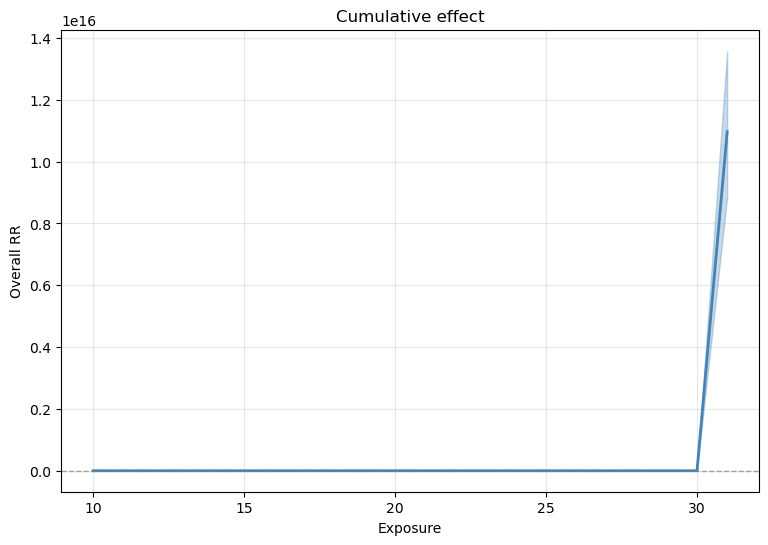

In [35]:
result.plot_overall()
plt.show()

In [ ]:
def graph_3Dplot(pred, mete_lst, i):
    if hasattr(pred, 'matRRfit'):
        # Z matrix shape is typically (len(pred.predvar), len(lags))
        # Let's align it so that Z is shaped as (len(pred.predvar), len(lags))
        n_rows, n_cols = pred.matRRfit.shape
                
        if n_rows == len(pred.predvar):
            Z = pred.matRRfit
        else:
            # If transposed, make sure rows correspond to temperature
            Z = pred.matRRfit.T
            n_rows, n_cols = Z.shape
    
        # 1. Dynamically build the coordinates based on actual matrix dimensions
        # This guarantees that the shape of your X, Y, and Z will match perfectly!
        temps_dimension = np.linspace(pred.predvar.min(), pred.predvar.max(), n_rows)
        lags_dimension = np.linspace(0, 21, n_cols)  # Maps your lag range (0 to 21) across the 5 columns
    
        # 2. Build the meshgrid matching (Temperatures x Lags)
        X, Y = np.meshgrid(temps_dimension, lags_dimension, indexing='ij')
    
        # 3. Plot the 3D Surface
        fig = plt.figure(figsize=(12, 8))
        ax = fig.add_subplot(111, projection='3d')
                
        # Plotting X, Y, and Z
        surf = ax.plot_surface(X, Y, Z, cmap=cm.coolwarm,
                            linewidth=0, antialiased=True, alpha=0.85)
    
        # Styling and Labels
        ax.set_xlabel({mete_lst[i]}, labelpad=10)
        ax.set_ylabel('Lag (Days)', labelpad=10)
        ax.set_zlabel('Relative Risk (RR)', labelpad=10)
        ax.set_title('3D Exposure-Lag-Response Association Surface', fontsize=14, pad=15)
                
        # Customize the Lag tick labels to represent your 0-21 lag period
        ax.set_yticks(np.linspace(0, 21, n_cols))
                
        # Add Colorbar
        fig.colorbar(surf, shrink=0.5, aspect=10, label='Relative Risk (RR)')
                
        plt.tight_layout()
        plt.show()
    else:
        print("No 3D matrix (matRRfit) found in predictions.")

In [ ]:
def graph_expplot(pred, mete_lst, i):
    cen = df[mete_lst[i]].median()
    sns.set_theme(style="whitegrid")
    
    plt.figure(figsize=(10, 6))
    
    # Plot the main cumulative RR curve
    plt.plot(pred.predvar, pred.allRRfit, color='#d95f02', lw=2.5, label='Cumulative RR')
    
    # Add 95% Confidence Interval as a shaded area
    if hasattr(pred, 'allRRlow') and hasattr(pred, 'allRRhigh'):
        plt.fill_between(pred.predvar, pred.allRRlow, pred.allRRhigh, 
                        color='#d95f02', alpha=0.15, label='95% CI')
    
    # Add reference line at RR = 1.0 (null association)
    plt.axhline(y=1.0, color='gray', linestyle='--', linewidth=1.2)
    
    plt.axvline(x=cen, color='black', linestyle=':', linewidth=1.2, label=f'Centering Temp ({cen:.1f}°C)')
    plt.title('Overall Cumulative Exposure-Response Association', fontsize=14, pad=15)
    plt.xlabel(mete_lst[i], fontsize=12)
    plt.legend(loc='best', frameon=True)
    
    plt.tight_layout()
    plt.show()

In [ ]:
def ai(pred, temp_base, temp_high):


    # 1. Grab your baseline data dimensions
    available_values = np.array(pred.predvar, dtype=float)  # Length 100
    true_num_lags = 5                                       # Hardcoded to 5 based on 500 total elements

    # Find the integer grid positions for your temperature thresholds
    idx_base = np.argmin(np.abs(available_values - temp_base))
    idx_high = np.argmin(np.abs(available_values - temp_high))

    # 2. Reshape the flat 1D arrays using the true matrix dimensions
    matfit_2d = np.array(pred.matfit).reshape((len(available_values), true_num_lags), order='F')
    matse_2d = np.array(pred.matse).reshape((len(available_values), true_num_lags), order='F')

    # 3. Extract the 5 lag steps safely from the clean 2D mapping
    log_rr_high = matfit_2d[idx_high, :]
    log_rr_base = matfit_2d[idx_base, :]
    contrast_se = matse_2d[idx_high, :]

    # 4. Calculate your 1°C non-linear contrast curves
    contrast_log_rr = log_rr_high - log_rr_base

    rr = np.exp(contrast_log_rr)
    low_ci = np.exp(contrast_log_rr - 1.96 * contrast_se)
    high_ci = np.exp(contrast_log_rr + 1.96 * contrast_se)

    # 5. Build your target visualization DataFrame (Manually creating Lags 0 to 4)
    df = pd.DataFrame({
        'Lag': np.array([0, 1, 2, 3, 4]), 
        'RR': rr, 
        'Low': low_ci, 
        'High': high_ci
    })

    return df



In [ ]:
def graph_lagplot(pred):
    temp_base = 15
    temp_high = 16
    lag_df = ai(pred, temp_base, temp_high)
    lags = np.array(pred.lag) 

    fig, ax = plt.subplots(figsize=(10, 5), facecolor='#ffffff')
    ax.set_facecolor('#f4f7f9')  # Matches your image background canvas

    # Plot the 95% Confidence Interval band
    ax.fill_between(lag_df['Lag'], lag_df['Low'], lag_df['High'], 
                    color='#1f77b4', alpha=0.15, label='95% CI')

    # Plot the main response line with node dots
    ax.plot(lag_df['Lag'], lag_df['RR'], color='#1f77b4', linewidth=2, 
            marker='o', markersize=6, label='Relative Risk (RR)')

    # Add the red baseline boundary at RR = 1.000
    ax.axhline(1.000, color='#dc3545', linestyle='--', linewidth=1.2, 
            label='Baseline Risk (No Effect)')

    # Grid, labels, and ticks matching your chart template
    ax.set_xlim(min(lags) - 0.2, max(lags) + 0.2)
    ax.set_xticks(range(lags[-1]+1))
    ax.grid(color='#e0e0e0', linestyle=':', linewidth=0.8)

    ax.set_title("Lag-Response Relationship of Temperature on Cases", fontsize=13, pad=15)
    ax.set_xlabel("Lag Time (Weeks)", fontsize=11, labelpad=8)
    ax.set_ylabel(f"Relative Risk per 1°C Increase ({int(temp_base)}°C to {int(temp_high)}°C)", fontsize=11, labelpad=8)
    ax.legend(loc='upper right', framealpha=0.8, edgecolor='#e0e0e0', fontsize=9)

    plt.tight_layout()
    plt.show()



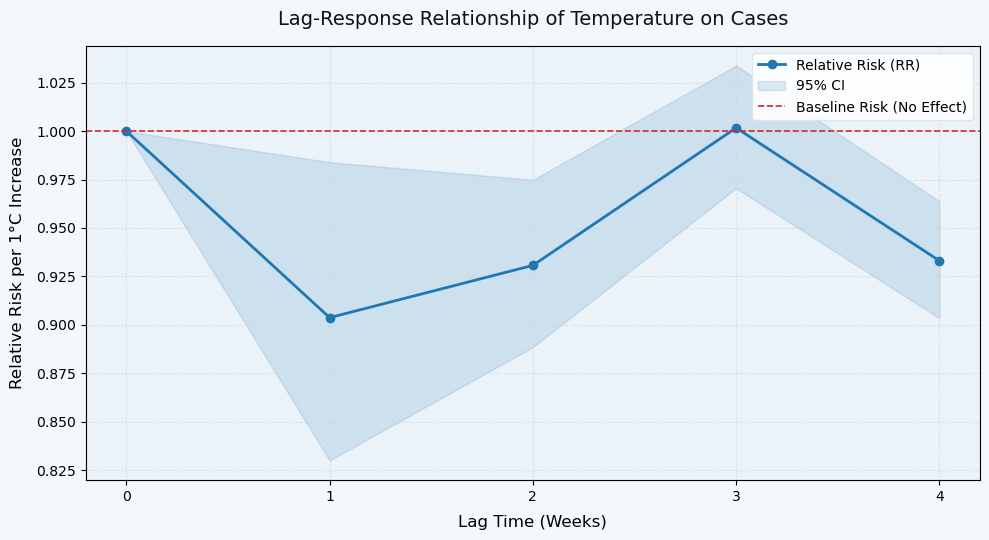

In [31]:


# 1. Convert your crosspred object to a flat DataFrame
df_preds = result.to_frame()

# 2. Extract a specific slice (e.g., your specific exposure value, like 25°C)
# Replace '25' with the target exposure value you are evaluating
slice_data = df_preds[df_preds["exposure"] == 25].sort_values("lag")

# 3. Create the styled figure
fig, ax = plt.subplots(figsize=(10, 5.5))

# Set the background color matching the image layout
ax.set_facecolor('#EBF3F9')       # Light blue plot area
fig.patch.set_facecolor('#F4F8FB') # Very light background border

# 4. Plot the components
# Relative Risk Line + Circle Markers
ax.plot(
    slice_data["lag"], slice_data["RR"], 
    color="#1F77B4", marker="o", linestyle="-", linewidth=2, 
    label="Relative Risk (RR)"
)

# Shaded 95% Confidence Interval
ax.fill_between(
    slice_data["lag"], slice_data["RR_low"], slice_data["RR_high"], 
    color="#1F77B4", alpha=0.15, 
    label="95% CI"
)

# Red Dashed Baseline Risk Line at Y = 1
ax.axhline(
    y=1.000, color="#D62728", linestyle="--", linewidth=1.2, 
    label="Baseline Risk (No Effect)"
)

# 5. Fine-Tune Grid and Aesthetics
ax.grid(True, which="both", color="white", linestyle="-", linewidth=1) # White grid bars
ax.grid(True, which="major", color="#D3D3D3", linestyle=":", linewidth=0.8) # Light overlay grid

# Ensure x-ticks show exact integer days
ax.set_xticks(slice_data["lag"].unique())

# Labels matching your layout text
ax.set_title("Lag-Response Relationship of Temperature on Cases", fontsize=14, pad=15, color="#111111")
ax.set_xlabel("Lag Time (Weeks)", fontsize=12, labelpad=8)
ax.set_ylabel("Relative Risk per 1°C Increase", fontsize=12, labelpad=8)

# Legend positioning (Upper Right corner matching the image style)
ax.legend(loc="upper right", framealpha=0.9, facecolor="white", edgecolor="#E2E2E2")

# Clean layout spacing
plt.tight_layout()
plt.show()


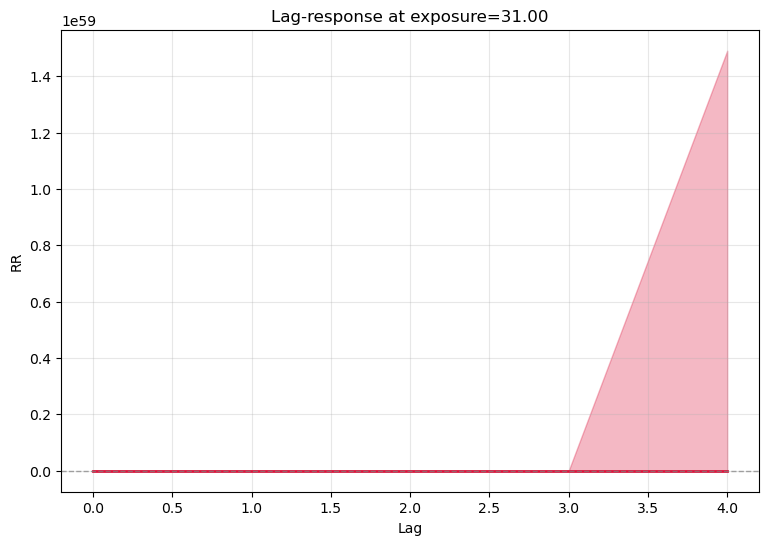

In [20]:
result.plot_slice(var=32, ci="area", color="crimson")
plt.show()

example from ai

c:\Users\yanss\anaconda3\Lib\site-packages\crossbasis\crossbasis.py:185: UserWarning: CrossBasis.transform: 21 rows with NaNs from lag padding (first 5 row indices: [0 1 2 3 4]). These rows will produce NaN in W.
  warnings.warn(
c:\Users\yanss\anaconda3\Lib\site-packages\crossbasis\crosspred.py:447: UserWarning: CrossPred.fit: 21 rows with NaNs from lag padding. These rows will need to be dropped before GLM fitting.
  warnings.warn(


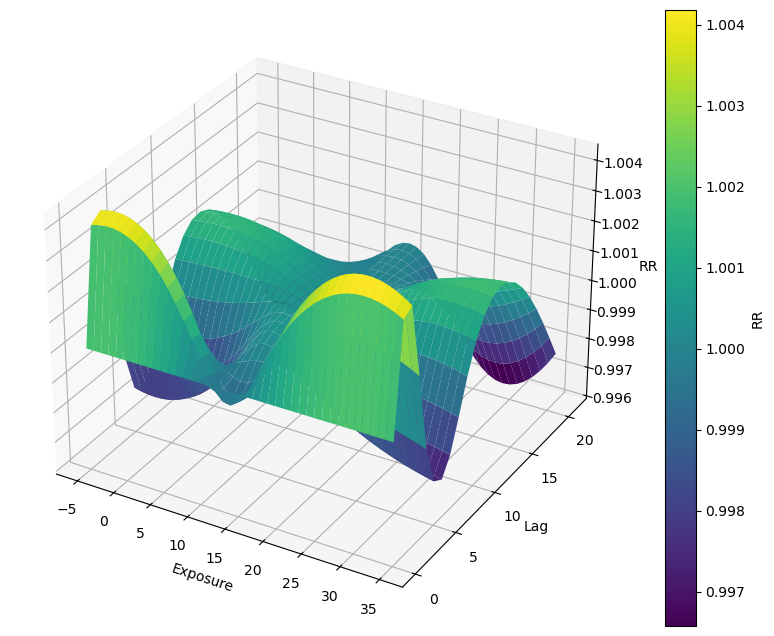

In [6]:
# test AI


# 0. Generate dummy time-series data (365 days)
np.random.seed(42)
temperature = np.random.randn(365) * 10 + 15  # Daily exposure
deaths = np.random.poisson(40, 365)       

# 1. Generate your cross-basis matrix
cp = CrossPred(var_basis="ns", var_df=5, lag_basis="ns", lag_df=4, max_lag=21)
W = cp.fit(temperature)

# 2. Put your outcome, confounders, and cross-basis matrix into a single DataFrame
df = pd.DataFrame({"deaths": deaths})

# Add the cross-basis columns dynamically
for i in range(W.shape[1]):
    df[f"cb_{i}"] = W[:, i]

# 3. Drop all rows that contain NaNs (this removes the initial lag days cleanly)
df_clean = df.dropna()

# 4. Extract the cleaned variables for statsmodels
y_clean = df_clean["deaths"]
X_clean = df_clean[[col for col in df_clean.columns if col.startswith("cb_")]]
X_clean = sm.add_constant(X_clean)

# 5. Fit your model safely
model = sm.GLM(y_clean, X_clean, family=sm.families.Poisson()).fit()



# 4. Predict and plot the exposure-lag-response surface
result = cp.predict(model, at=np.arange(-5, 36))
result.plot_3d()       # Generates a 3D surface plot
plt.show()


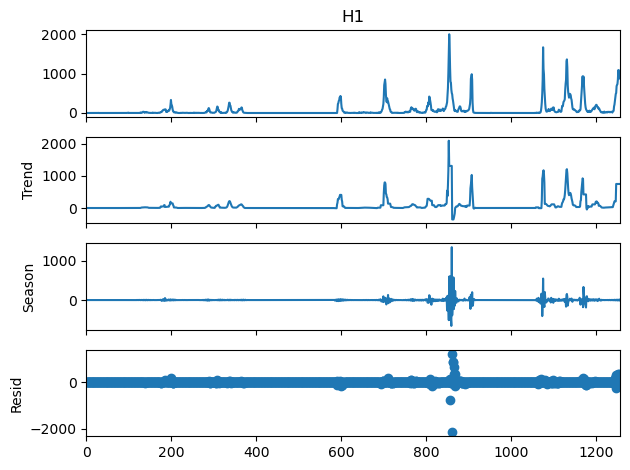

In [8]:
df = pd.read_csv("data.csv")


stl = STL(df["H1"], period=4, robust=True)
result = stl.fit()
result.plot()
plt.show()


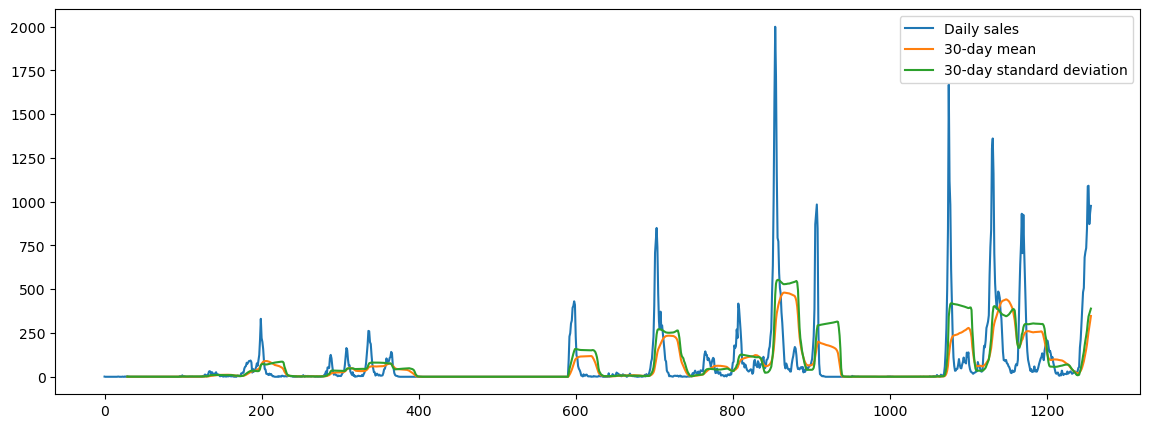

In [9]:
rolling_mean = df["H1"].rolling(30).mean()
rolling_std = df["H1"].rolling(30).std()

plt.figure(figsize=(14, 5))
plt.plot(df["H1"], label="Daily sales")
plt.plot(rolling_mean, label="30-day mean")
plt.plot(rolling_std, label="30-day standard deviation")
plt.legend()
plt.show()

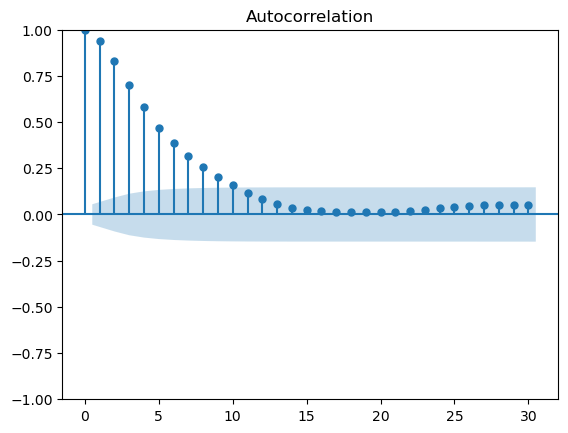

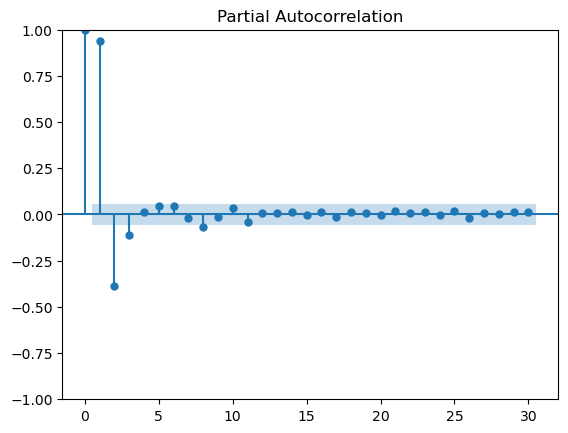

In [10]:


series = df["H1"]

plot_acf(series, lags=30)
plt.show()

plot_pacf(series, lags=30, method="ywm")
plt.show()